In [1]:
from __future__ import annotations
from typing import TypedDict, List, Annotated, Literal, Optional
import operator

from pydantic import Field, BaseModel
from langgraph.graph import START, END, StateGraph
from langgraph.types import Send

from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage, HumanMessage

from langchain_community.tools.tavily_search import TavilySearchResults

from dotenv import load_dotenv
load_dotenv()

from pathlib import Path
import os

/tmp/ipykernel_31429/2524886697.py:12: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools.tavily_search import TavilySearchResults


In [2]:
class Task(BaseModel):
    id: int
    title: str

    goal: str = Field(
        description="One sentence describing what the reader should be able to do/understand after this section.",
    )
    bullets: List[str] = Field(
        min_length=3,
        max_length=5,
        description="3–5 concrete, non-overlapping subpoints to cover in this section.",
    )
    target_words: int = Field(description="Target word count for this section (120–300).")

    tags: List[str] = Field(default_factory=list)
    requires_research: bool = False
    requires_citations: bool = False
    requires_code: bool = False


class Plan(BaseModel):
    blog_title: str
    audience: str
    tone: str
    blog_kind: Literal["explainer", "tutorial", "news_roundup", "comparison", "system_design"] = "explainer"
    constraints: List[str] = Field(default_factory=list)
    tasks: List[Task]


class EvidenceItem(BaseModel):
    title: str
    url: str
    published_at: Optional[str] = None  # keep if Tavily provides; DO NOT rely on it
    snippet: Optional[str] = None
    source: Optional[str] = None


class RouterDecision(BaseModel):
    needs_research: bool
    mode: Literal["closed_book", "hybrid", "open_book"]
    queries: List[str] = Field(default_factory=list)


class EvidencePack(BaseModel):
    evidence: List[EvidenceItem] = Field(default_factory=list)

class ImageSpec(BaseModel):
    placeholder: str = Field(description="examples= [[IMAGE_1]]")
    filename: str = Field(description="Save under images/ example = abc_flow.png")
    alt: str
    caption: str
    prompt: str = Field(description="Prompt to send to the image model")
    size: Literal["1024x1024", "1024x1536", "1536x1536"] = "1024x1024"
    quality: Literal["low", "medium", "high"] = "medium"

class GlobalImagePlan(BaseModel):
    md_with_placeholders: str
    images: List[ImageSpec] = Field(default_factory=list)

In [3]:
class State(TypedDict):
    topic: str

    # routing / research
    mode: str
    needs_research: bool
    queries: List[str]
    evidence: List[EvidenceItem]
    plan: Optional[Plan]

    # workers
    sections: Annotated[List[tuple[int, str]], operator.add]  # (task_id, section_md)

    # reducer / image
    merged_md: str
    md_with_placeholders: str
    image_specs: List[dict]

    final: str    

In [4]:
llm = ChatGroq(model="openai/gpt-oss-120b")

In [5]:
ROUTER_SYSTEM = """You are a routing module for a technical blog planner.

Decide whether web research is needed BEFORE planning.

Modes:
- closed_book (needs_research=false):
  Evergreen topics where correctness does not depend on recent facts (concepts, fundamentals).
- hybrid (needs_research=true):
  Mostly evergreen but needs up-to-date examples/tools/models to be useful.
- open_book (needs_research=true):
  Mostly volatile: weekly roundups, "this week", "latest", rankings, pricing, policy/regulation.

If needs_research=true:
- Output 3–5 high-signal queries.
- Queries should be scoped and specific (avoid generic queries like just "AI" or "LLM").
- If user asked for "last week/this week/latest", reflect that constraint IN THE QUERIES.
"""

def router_node(state:State) -> dict:
    topic = state['topic']
    decider = llm.with_structured_output(RouterDecision)
    decision = decider.invoke(
        [
            SystemMessage(content=ROUTER_SYSTEM),
            HumanMessage(content=f"Topic: {topic}")
        ]
    )

    return{
        "needs_research":decision.needs_research,
        "mode":decision.mode,
        "queries":decision.queries
    }

def route_next(state:State) -> str:
    return "research" if state['needs_research'] else "orchestrator"

RESEARCH NODE

In [6]:
def _tavily_search(query: str, max_results: int = 3) -> List[dict]:
    
    tool = TavilySearchResults(max_results=max_results)
    results = tool.invoke({"query": query})

    normalized: List[dict] = []
    for r in results or []:
        normalized.append(
            {
                "title": r.get("title") or "",
                "url": r.get("url") or "",
                "snippet": r.get("content") or r.get("snippet") or "",
                "published_at": r.get("published_date") or r.get("published_at"),
                "source": r.get("source"),
            }
        )
    return normalized


RESEARCH_SYSTEM = """You are a research synthesizer for technical writing.

Given raw web search results, produce a deduplicated list of EvidenceItem objects.

Rules:
- Only include items with a non-empty url.
- Prefer relevant + authoritative sources (company blogs, docs, reputable outlets).
- If a published date is explicitly present in the result payload, keep it as YYYY-MM-DD.
  If missing or unclear, set published_at=null. Do NOT guess.
- Keep snippets short.
- Deduplicate by URL.
"""

def research_node(state: State) -> dict:

    queries = (state.get("queries", [] or []))
    max_results = 2

    raw_results: List[dict] = []

    for q in queries:
        raw_results.extend(_tavily_search(q, max_results=max_results))

    if not raw_results:
        return {"evidence": []}

    extractor = llm.with_structured_output(EvidencePack)
    pack = extractor.invoke(
        [
            SystemMessage(content=RESEARCH_SYSTEM),
            HumanMessage(content=f"Raw results:\n{raw_results}"),
        ]
    )

    # Deduplicate by URL
    dedup = {}
    for e in pack.evidence:
        if e.url:
            dedup[e.url] = e

    return {"evidence": list(dedup.values())}

ORCHESTRATOR - MAKES PLAN FOR THE BLOG AND STORES IN PLAN OBJECT

In [7]:
ORCHESTRATION_SYSTEM = """ 
"You are a senior technical writer and developer advocate. Your job is to produce a "
                    "highly actionable outline for a technical blog post.\n\n"
                    "Hard requirements:\n"
                    "- Create 3-5 sections (tasks) that fit a technical blog.\n"
                    "- Each section must include:\n"
                    "  1) goal (1 sentence: what the reader can do/understand after the section)\n"
                    "  2) 2-3 bullets that are concrete, specific, and non-overlapping\n"
                    "  3) target word count (120–300)\n"
                    "- Include EXACTLY ONE section with section_type='common_mistakes'.\n\n"
                    "Make it technical (not generic):\n"
                    "- Assume the reader is a developer; use correct terminology.\n"
                    "- Prefer design/engineering structure: problem → intuition → approach → implementation → "
                    "trade-offs → testing/observability → conclusion.\n"
                    "- Bullets must be actionable and testable (e.g., 'Show a minimal code snippet for X', "
                    "'Explain why Y fails under Z condition', 'Add a checklist for production readiness').\n"
                    "- Explicitly include at least ONE of the following somewhere in the plan (as bullets):\n"
                    "  * a minimal working example (MWE) or code sketch\n"
                    "  * edge cases / failure modes\n"
                    "  * performance/cost considerations\n"
                    "  * security/privacy considerations (if relevant)\n"
                    "  * debugging tips / observability (logs, metrics, traces)\n"
                    "- Avoid vague bullets like 'Explain X' or 'Discuss Y'. Every bullet should state what "
                    "to build/compare/measure/verify.\n\n"
                    "Ordering guidance:\n"
                    "- Start with a crisp intro and problem framing.\n"
                    "- Build core concepts before advanced details.\n"
                    "- Include one section for common mistakes and how to avoid them.\n"
                    "- End with a practical summary/checklist and next steps.\n\n"
                    "Output must strictly match the Plan schema."
            """

def orchestrator_node(state: State):
    planner = llm.with_structured_output(Plan)

    evidence = state.get("evidence", [])
    mode = state.get("mode", "closed_book")

    plan = planner.invoke(
        [
            SystemMessage(content=ORCHESTRATION_SYSTEM),
            HumanMessage(
                content=(
                    f"Topic: {state['topic']}\n"
                    f"Mode: {mode}\n\n"
                    f"Evidence (ONLY use for fresh claims; may be empty):\n"
                    f"{[e.model_dump() for e in evidence]}"
                )
            ),
        ]
    )

    return {"plan": plan}

FANOUT - THE NUMBER OF WORKER DEPENDS ON THE NUMBER OF BLOG SECTION, IT IS DECIDED DYNAMICALLY

- Each worker knows it's task to perform, entire blog topic, entire blog plan; So that it can do it's worker properly

In [8]:
def fanout(state: State):
    return [
        Send(
            "worker",
            {
                "task": task.model_dump(),
                "topic": state["topic"],
                "mode": state["mode"],
                "plan": state["plan"].model_dump(),
                "evidence": [e.model_dump() for e in state.get("evidence", [])],
            },
        )
        for task in state["plan"].tasks
    ]

In [ ]:
WORKER_SYSTEM = """You are a senior technical writer and developer advocate.
Write ONE section of a technical blog post in Markdown.

Hard constraints:
- Follow the provided Goal and cover ALL Bullets in order (do not skip or merge bullets).
- Stay close to Target words (±15%).
- Output ONLY the section content in Markdown (no blog title H1, no extra commentary).
- Start with a '## <Section Title>' heading.

Scope guard:
- If blog_kind == "news_roundup": do NOT turn this into a tutorial/how-to guide.
  Do NOT teach web scraping, RSS, automation, or "how to fetch news" unless bullets explicitly ask for it.
  Focus on summarizing events and implications.

Grounding policy:
- If mode == open_book:
  - Do NOT introduce any specific event/company/model/funding/policy claim unless it is supported by provided Evidence URLs.
  - For each event claim, attach a source as a Markdown link: ([Source](URL)).
  - Only use URLs provided in Evidence. If not supported, write: "Not found in provided sources."
- If requires_citations == true:
  - For outside-world claims, cite Evidence URLs the same way
- Evergreen reasoning is OK without citations unless requires_citations is true.

Code:
- If requires_code == true, include at least one minimal, correct code snippet relevant to the bullets.

Style:
- Short paragraphs, bullets where helpful, code fences for code.
- Avoid fluff/marketing. Be precise and implementation-oriented.
"""

def worker_node(payload: dict) -> dict:
    
    task = Task(**payload["task"])
    plan = Plan(**payload["plan"])
    evidence = [EvidenceItem(**e) for e in payload.get("evidence", [])]
    topic = payload["topic"]
    mode = payload.get("mode", "closed_book")

    bullets_text = "\n- " + "\n- ".join(task.bullets)

    evidence_text = ""
    if evidence:
        evidence_text = "\n".join(
            f"- {e.title} | {e.url} | {e.published_at or 'date:unknown'}".strip()
            for e in evidence[:20]
        )

    response = llm.invoke(
        [
            SystemMessage(content=WORKER_SYSTEM),
            HumanMessage(
                content=(
                    f"Blog title: {plan.blog_title}\n"
                    f"Audience: {plan.audience}\n"
                    f"Tone: {plan.tone}\n"
                    f"Blog kind: {plan.blog_kind}\n"
                    f"Constraints: {plan.constraints}\n"
                    f"Topic: {topic}\n"
                    f"Mode: {mode}\n\n"
                    f"Section title: {task.title}\n"
                    f"Goal: {task.goal}\n"
                    f"Target words: {task.target_words}\n"
                    f"Tags: {task.tags}\n"
                    f"requires_research: {task.requires_research}\n"
                    f"requires_citations: {task.requires_citations}\n"
                    f"requires_code: {task.requires_code}\n"
                    f"Bullets:{bullets_text}\n\n"
                    f"Evidence (ONLY use these URLs when citing):\n{evidence_text}\n"
                )
            ),
        ]
    )    
    
    # Convert Gemini's content into a normal string
    if isinstance(response.content, str):
        section_md = response.content.strip()

    elif isinstance(response.content, list):
        section_md = "\n".join(
            block["text"]
            for block in response.content
            if isinstance(block, dict)
            and block.get("type") == "text"
            and block.get("text")
        ).strip()

    else:
        raise TypeError(
            f"Unexpected response.content type: {type(response.content)}"
        )

    return {"sections": [(task.id, section_md)]}

REDUCER - STITCHES ALL THE SECTIONS FROM THE WOKER AND CONCATINATE'S IT

- Subgraph 
- merge_content -> decide_images -> generate_and_place_images

In [ ]:
def merge_content(state: State) -> dict:

    plan = state["plan"]
    
    ordered_sections = [md for _, md in sorted(state["sections"], key=lambda x: x[0])]
    body = "\n\n".join(ordered_sections).strip()
    merged_md = f"# {plan.blog_title}\n\n{body}\n"

    return {"merged_md":merged_md}

DECIDE_IMAGES_SYSTEM = """You are an expert technical editor.
Decide if images/diagrams are needed for THIS blog.

Rules:
- Max 2 images total.
- Each image must materially improve understanding (diagram/flow/table-like visual).
- Insert placeholders exactly: [[IMAGE_1]], [[IMAGE_2]].
- If no images needed: md_with_placeholders must equal input and images=[].
- Avoid decorative images; prefer technical diagrams with short labels.
Return strictly GlobalImagePlan.
"""

# ADD PLACEHOLDERS
def decide_images(state: State) -> dict:
    
    planner = llm.with_structured_output(GlobalImagePlan)
    merged_md = state["merged_md"]
    plan = state["plan"]
    assert plan is not None

    image_plan = planner.invoke(
        [
            SystemMessage(content=DECIDE_IMAGES_SYSTEM),
            HumanMessage(
                content=(
                    f"Blog kind: {plan.blog_kind}\n"
                    f"Topic: {state['topic']}\n\n"
                    "Insert placeholders + propose image prompts.\n\n"
                    f"{merged_md}"
                )
            ),
        ]
    )

    return{
        "md_with_placeholders":image_plan.md_with_placeholders,
        "image_specs": [img.model_dump() for img in image_plan.images]
    }

from huggingface_hub import InferenceClient

def _huggingface_generate_image(prompt: str):
    """
    Generate an image using FLUX.1-schnell through
    Hugging Face Inference Providers.

    Requires:
        HUGGINGFACEHUB_API_TOKEN
    """

    api_key = os.environ.get("HUGGINGFACEHUB_API_TOKEN")

    if not api_key:
        raise RuntimeError(
            "HUGGINGFACEHUB_API_TOKEN is not set."
        )

    client = InferenceClient(
        api_key=api_key
    )

    image = client.text_to_image(
        prompt=prompt,
        model="black-forest-labs/FLUX.1-schnell"
    )

    return image

# GENERATE AND REPLACE THE PLACEHOLDER
def generate_and_place_images(state: State) -> dict:

    plan = state["plan"]
    assert plan is not None

    md = state.get("md_with_placeholders") or state["merged_md"]
    image_specs = state.get("image_specs", []) or []

    # If no images requested, just write merged markdown
    if not image_specs:
        filename = f"{plan.blog_title}.md"
        Path(filename).write_text(md, encoding="utf-8")
        return {"final": md}

    images_dir = Path("images")
    images_dir.mkdir(exist_ok=True)

    for spec in image_specs:

        placeholder = spec["placeholder"]
        filename = spec["filename"]
        out_path = images_dir / filename

        # Generate only if needed
        if not out_path.exists():

            try:

                image = _huggingface_generate_image(
                    spec["prompt"]
                )

                image.save(out_path)

            except Exception as e:

                # graceful fallback
                prompt_block = (
                    f"> **[IMAGE GENERATION FAILED]** "
                    f"{spec.get('caption', '')}\n>\n"
                    f"> **Alt:** {spec.get('alt', '')}\n>\n"
                    f"> **Prompt:** {spec.get('prompt', '')}\n>\n"
                    f"> **Error:** {e}\n"
                )

                md = md.replace(
                    placeholder,
                    prompt_block
                )

                continue

        img_md = (
            f"![{spec['alt']}](images/{filename})\n"
            f"*{spec['caption']}*"
        )

        md = md.replace(
            placeholder,
            img_md
        )

    filename = f"{plan.blog_title}.md"

    Path(filename).write_text(
        md,
        encoding="utf-8"
    )

    return {"final": md}

SUBGRAPH

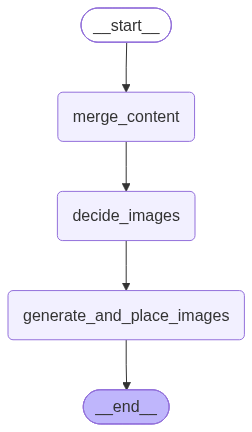

In [11]:
reducer_graph = StateGraph(State)
reducer_graph.add_node("merge_content",merge_content)
reducer_graph.add_node("decide_images",decide_images)
reducer_graph.add_node("generate_and_place_images",generate_and_place_images)

reducer_graph.add_edge(START,"merge_content")
reducer_graph.add_edge("merge_content","decide_images")
reducer_graph.add_edge("decide_images","generate_and_place_images")
reducer_graph.add_edge("generate_and_place_images",END)

reducer_subgragh = reducer_graph.compile()

reducer_subgragh

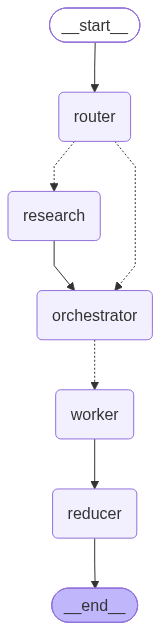

In [12]:
g = StateGraph(State)
g.add_node("router", router_node)
g.add_node("research", research_node)
g.add_node("orchestrator", orchestrator_node)
g.add_node("worker", worker_node)
g.add_node("reducer", reducer_subgragh)

g.add_edge(START, "router")
g.add_conditional_edges("router", route_next, {"research": "research", "orchestrator": "orchestrator"})
g.add_edge("research", "orchestrator")

g.add_conditional_edges("orchestrator", fanout, ["worker"])
g.add_edge("worker", "reducer")
g.add_edge("reducer", END)

app = g.compile()
app

In [13]:
def run(topic: str):
    out = app.invoke(
        {
            "topic":topic,
            "mode":"",
            "needs_research":False,
            "queries":[],
            "evidence":[],
            "plan":None,
            "sections":[],
            "merge_content":"",
            "md_with_placeholders":"",
            "image_specs":[],
            "final":""
        }
    )

    return out

In [15]:
run("Self Attention in Transformer Architecture")

BadRequestError: Error code: 400 - {'error': {'message': 'Failed to parse tool call arguments as JSON', 'type': 'invalid_request_error', 'code': 'tool_use_failed', 'failed_generation': '{"name": "GlobalImagePlan", "arguments": {\n  "images": [\n    {\n      "alt": "Comparison of RNN sequential processing versus self‑attention parallel matrix computation",\n      "caption": "RNN processes tokens one‑by‑one while self‑attention computes a full token‑by‑token score matrix in parallel.",\n      "filename": "rnn_vs_self_attention.png",\n      "placeholder": "[[IMAGE_1]]",\n      "prompt": "Create a simple technical diagram showing two columns. Left column: an RNN processing a 5‑token sequence sequentially, with arrows from one token block to the next labeled \'hidden state\'. Right column: self‑attention computing a 5×5 score matrix in parallel, displayed as a grid of squares. Label tokens at top and side, and add titles \'RNN\' and \'Self‑Attention\'. Use minimal color, clear block labels,